In [ ]:
# --- project bootstrap ---
# common/ holds the shared modules (geom_utils, mosaic_utils*).
import sys, pathlib
_common = str(pathlib.Path.cwd().parent / "common")
if _common not in sys.path:
    sys.path.insert(0, _common)
# -------------------------

In [7]:
!which python3
import lsst.daf.butler as dafButler
from lsst.summit.utils.utils import getCameraFromInstrumentName

import numpy as np


from astropy.time import Time
from astropy.coordinates import EarthLocation, SkyCoord, AltAz 
from astropy import units as u
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt
from astropy.time import Time, TimeDelta
from matplotlib.patches import Rectangle 
from skyfield.api import load
from lsst.summit.utils import ConsDbClient

import geom_utils as gu

URL = "http://consdb-pq.consdb:8080/consdb"  
os.environ["no_proxy"] += ",.consdb"
cdb_client = ConsDbClient(URL)
visit=None

query_table = f"""
        SELECT
            visit_id AS visit_id,
            physical_rotator_angle  AS rot_ang
        FROM
            cdb_lsstcam.visit1_quicklook

""" 
rotation_df = cdb_client.query(query_table).to_pandas()
camera = getCameraFromInstrumentName("LSSTCam")


/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.1.0-exact/bin/python3


In [8]:
visit_list=[2026012800160, 2025112600374, 2026012800162, 2026011900181,2026011900183,2026011900355, 2026011800206,  2025112700368,2025120900408, 2025112600459, 2026011700312,] #,2025092100248,2025091800171]
# visit_list=range(2026021600539,2026021600555)

In [ ]:
max_dist = 3 * u.deg
limit = 5
arr = []

# ------------------------------------------------------------
# Convenzioni NSC (da NSQ_source.txt / ADD_FIELD_SOURCE.ZPL)
# ------------------------------------------------------------
EPD_MM = 8400.0                  # Entrance pupil diameter
PUPIL_RADIUS_MM = EPD_MM / 2.0
SOURCE_Z_MM = -9000.0            # Z della sorgente
SOURCE_TILT_Z_DEG = -180.0       # Tilt Z fisso


def source_ellipse_params(field_deg, clock_deg):
    """Geometria di una Source Ellipse off-axis, come in ADD_FIELD_SOURCE.ZPL.

    field_deg: angolo off-axis rispetto all'asse ottico
    clock_deg: clock angle attorno all'asse ottico
    """
    field_rad = np.deg2rad(field_deg)
    clock_rad = np.deg2rad(clock_deg)

    radius = abs(SOURCE_Z_MM) * np.tan(field_rad)

    x_pos = -radius * np.cos(clock_rad)
    y_pos = -radius * np.sin(clock_rad)

    tilt_x = -field_deg * np.sin(clock_rad)
    tilt_y = field_deg * np.cos(clock_rad)

    # Proiezione sul piano XY di una pupilla circolare inclinata di field_deg
    x_half_radius = PUPIL_RADIUS_MM * np.sqrt(
        np.sin(clock_rad) ** 2 + np.cos(field_rad) ** 2 * np.cos(clock_rad) ** 2
    )
    y_half_radius = PUPIL_RADIUS_MM * np.sqrt(
        np.cos(clock_rad) ** 2 + np.cos(field_rad) ** 2 * np.sin(clock_rad) ** 2
    )

    return dict(
        x=float(x_pos), y=float(y_pos), z=float(SOURCE_Z_MM),
        tilt_x=float(tilt_x), tilt_y=float(tilt_y), tilt_z=float(SOURCE_TILT_Z_DEG),
        x_half_radius=float(x_half_radius), y_half_radius=float(y_half_radius),
    )


for visit in visit_list:
    if visit > 2025110000000:
        butler = dafButler.Butler(
            "embargo",
            collections=["LSSTCam/runs/nightlyValidation", "LSSTCam/raw/all"],
            instrument="LSSTCam",
        )
    else:
        butler = dafButler.Butler(
            "main",
            collections=["LSSTCam/raw/all", "u/ataranto/general_outputs"],
            instrument="LSSTCam",
        )

    try:
        rot_ang = rotation_df['rot_ang'][rotation_df['visit_id'].values == visit].values[0]
        if type(rot_ang) != float:
            rot_ang = float(input(f"{visit} manual rot input from stellarium...  "))
    except Exception:
        rot_ang = float(input(f"{visit} manual rot input from stellarium...  "))

    print(f"Processing visit {visit}...")
    t = butler.get("raw.visitInfo", exposure=visit, detector=94).date.toAstropy()
    ra = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getRa().asDegrees()
    dec = butler.get("raw.visitInfo", exposure=visit, detector=94).boresightRaDec.getDec().asDegrees()
    info = butler.get('raw.visitInfo', detector=94, exposure=visit)
    st_time = str(info.date).split('"')[1]

    center = SkyCoord(ra=ra, dec=dec, unit=(u.deg, u.deg), frame='icrs')

    try:
        brightest_stars = gu.find_bright_stars(
            center,
            max_dist,
            sorting='Vmag',
            mag_filter_dict={"Vmag": "<8"},
            limit=limit,
        )
    except Exception as e:
        print(f"Error finding bright stars for visit {visit}: {e}")
        brightest_stars = None

    zpl_macro = f"add_nsc_sources_visit{visit}.ZPL"

    with open(zpl_macro, "w", encoding="utf-8") as f:
        f.write("! ------------------------------------------------------------\n")
        f.write("! Auto-generated by sky_geometry_nsc.ipynb\n")
        f.write(f"! VISIT {visit}\n")
        f.write("!\n")
        f.write("! Appends one Source Ellipse per bright star at the end of the\n")
        f.write("! Non-Sequential Component editor, using the off-axis field and\n")
        f.write("! clock angle measured on sky.\n")
        f.write("!\n")
        f.write(f"! EPD [mm]          = {EPD_MM:.1f}\n")
        f.write(f"! Pupil radius [mm] = {PUPIL_RADIUS_MM:.1f}\n")
        f.write(f"! Source Z [mm]     = {SOURCE_Z_MM:.1f}\n")
        f.write(f"! Source Tilt Z     = {SOURCE_TILT_Z_DEG:.1f} deg\n")
        f.write("! ------------------------------------------------------------\n\n")

        if brightest_stars is not None:
            for i, star in enumerate(brightest_stars, start=1):
                starCoord = SkyCoord(
                    ra=star['_RA.icrs'],
                    dec=star['_DE.icrs'],
                    unit=(u.deg, u.deg),
                    frame='icrs',
                )
                field_deg = float(star['Radial_Distance'])
                clock_deg = float(gu.get_pos_ang(starCoord, center, "rubin", st_time).to(u.deg).value)
                starVMag = star['Vmag']

                p = source_ellipse_params(field_deg, clock_deg)

                print(
                    f"\t{i} - HIP {int(star['HIP'])}, Vmag: {starVMag:.3f}, "
                    f"field={field_deg:.3f} deg, clock={clock_deg:.3f} deg, "
                    f"X={p['x']:.1f}, Y={p['y']:.1f}"
                )

                f.write(f"! --- Star {i}: HIP {int(star['HIP'])}, Vmag {starVMag:.3f} ---\n")
                f.write(f"! Field off-axis = {field_deg:.6f} deg, Clock = {clock_deg:.6f} deg\n")
                f.write("new_object = NOBJ(1) + 1\n")
                f.write("INSERTOBJECT 1, new_object\n")
                f.write('SETNSCPROPERTY 1, new_object, 0, 0, "NSC_SRCE"\n')
                f.write(f"SETNSCPOSITION 1, new_object, 1, {p['x']:.8f}\n")
                f.write(f"SETNSCPOSITION 1, new_object, 2, {p['y']:.8f}\n")
                f.write(f"SETNSCPOSITION 1, new_object, 3, {p['z']:.8f}\n")
                f.write(f"SETNSCPOSITION 1, new_object, 4, {p['tilt_x']:.8f}\n")
                f.write(f"SETNSCPOSITION 1, new_object, 5, {p['tilt_y']:.8f}\n")
                f.write(f"SETNSCPOSITION 1, new_object, 6, {p['tilt_z']:.8f}\n")
                f.write(f"SETNSCPARAMETER 1, new_object, 6, {p['x_half_radius']:.8f}\n")
                f.write(f"SETNSCPARAMETER 1, new_object, 7, {p['y_half_radius']:.8f}\n")
                f.write('PRINT "Added source for HIP ' + f"{int(star['HIP'])}" + ' as object ", new_object\n')
                f.write("\n")
        else:
            f.write("! No stars found for this visit.\n\n")

        f.write("UPDATE\n")
        f.write("END\n")

    print(f"ZEMAX ROTATOR ANGLE : {rot_ang:.2f}")
    print(f"ZPL macro written: {zpl_macro}")
    arr.append(rot_ang)

In [6]:
visits_query = f'''
    SELECT exposure_id, s_ra, s_dec
    FROM cdb_lsstcomcam.exposure
'''
visitAll = cdb_client.query(visits_query).to_pandas().dropna()
visitAll

,exposure_id,s_ra,s_dec
2743,2023053100039,206.638389,-40.049675
2752,2023053100044,206.638252,-40.049682
2783,2023053100029,206.638377,-40.049672
2784,2023053100034,206.638624,-40.049676
2823,2023053100032,206.638407,-40.049676
...,...,...,...
29864,2024121100516,63.906342,-33.793128
29865,2024121100563,94.950825,-24.999954
29867,2024121100570,95.027382,-25.036528
29868,2024121100464,62.544278,-41.614124


In [9]:
from astropy.coordinates import SkyCoord
import astropy.units as u
ra_ref=92
dec_ref=-25
coords = SkyCoord(ra=visitAll["s_ra"].values*u.deg, dec=visitAll["s_dec"].values*u.deg)
ref = SkyCoord(ra=ra_ref*u.deg, dec=dec_ref*u.deg)

sep = coords.separation(ref)

df_filtered = visitAll[sep.deg <= 0.2]


In [10]:
print(*df_filtered['exposure_id'])

2024120100426 2024120100418 2024120100411 2024120100440 2024120100412 2024120100408 2024120100407 2024120100425 2024120100405 2024120100416 2024120100421 2024120100419 2024120100415 2024120100422 2024120100423 2024120100424 2024120100430 2024120100428 2024120100429 2024120100433 2024120100404 2024120100439 2024120100406 2024120100409 2024120100410 2024120100413 2024120100417 2024120100414 2024120100420 2024120100427 2024120100431 2024120100432 2024120100438 2024120100434 2024120100435 2024120100437 2024120100436


In [ ]:
visitimage_refs = butler.query_datasets('visit_image',
                                        where="visit.region OVERLAPS POINT(ra, dec) "
                                        f"and band='{my_band}'",
                                        bind={'ra': ra, 'dec': dec},
                                        order_by=['visit', 'detector'],
                                        with_dimension_records=True,
                                        limit=1)

(array([1., 0., 0., 0., 0., 0., 0., 0., 1., 1., 0., 2., 0., 0., 0., 0., 0.,
        0., 0., 1.]),
 array([-27.99452819, -24.58730178, -21.18007537, -17.77284896,
        -14.36562255, -10.95839615,  -7.55116974,  -4.14394333,
         -0.73671692,   2.67050949,   6.0777359 ,   9.48496231,
         12.89218872,  16.29941513,  19.70664154,  23.11386795,
         26.52109436,  29.92832077,  33.33554718,  36.74277359,
         40.15      ]),
 <BarContainer object of 20 artists>)

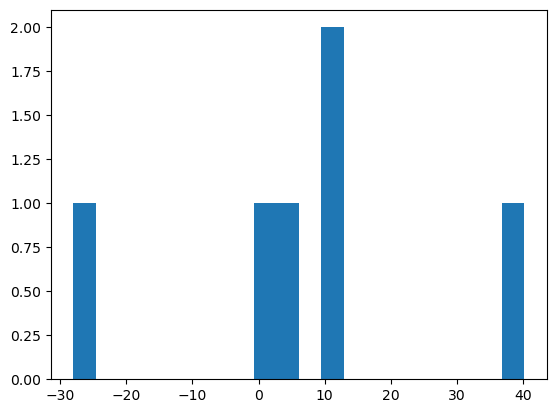

In [10]:
plt.hist(arr,bins=20)